---
# <div align="center"><font color='blue'> COSC 2779/2972 | Deep Learning </font></div>
## <div align="center"><font color='blue'> Week 11 Lab: Representation Learning & Self-Supervised Learning with ECG Signals</font></div>
---


Most ML systems in this course have been trained with labelled data: `input → label`. But in many real-world settings — especially healthcare — labels are expensive, scarce, noisy, or unavailable.

Modern AI systems often learn useful **representations** first, then adapt them to downstream tasks:

```
Unlabelled data → Learn representation → Apply to many tasks
```

This is exactly how foundation models work (Week 9). This week, we build the same idea from scratch: learn representations from ECG signals without labels, then use them for anomaly detection and classification.


## 🎯 Learning Objectives

By the end of this lab, you should be able to:

- Explain the difference between supervised learning, representation learning, and self-supervised learning
- Understand why learning good representations is often more important than learning a specific task
- Train a 1D convolutional autoencoder on ECG signals
- Visualise learned embeddings using dimensionality reduction
- Use reconstruction error for anomaly detection
- Evaluate anomaly detection systems with appropriate metrics (precision, recall, ROC-AUC)
- Investigate transfer learning using self-supervised representations
- Perform error analysis on anomaly detection systems

**Prerequisites:** Weeks 3–10 (CNNs, transfer learning, transformers, foundation models, generative models)

**Duration:** ~2–3 hours

---

## Dataset: ECG5000

The ECG5000 dataset contains 5,000 heartbeat recordings from the PhysioNet BIDMC Congestive Heart Failure Database. Each sample:
- Is a single heartbeat with **140 time steps**
- Has a label: **Normal** (class 1, ~58%) or **Abnormal** (classes 2–5, ~42%)
- The abnormal classes include R-on-T premature ventricular contractions, PVCs, supraventricular premature beats, and unclassified beats

For representation learning, we initially **ignore the labels** and learn purely from the signal structure.

## Setup

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, classification_report,
    accuracy_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


---
# Part 1: What Is Representation Learning?

### Traditional ML vs Deep Learning

| Approach | Pipeline |
|---|---|
| Traditional ML | Raw signal → **Handcrafted features** (peak height, interval, slope) → Classifier |
| Deep Learning | Raw signal → **Learned representation** → Classifier |
| Self-supervised | Raw signal → **Learned representation** (no labels) → Many downstream tasks |

A good representation can be reused for classification, clustering, retrieval, similarity search, and anomaly detection. This is the same principle behind foundation models (Week 9) — but applied to a specific domain.

### Why ECG?

Medical data is a perfect example of where labels are scarce:
- Expert cardiologists must annotate each heartbeat, expensive and time-consuming
- Rare conditions have very few labelled examples
- Labelling errors can have life-or-death consequences
- But **unlabelled ECG recordings** are abundant, every hospital collects them continuously

### 🤔 Questions

1. Why might labelled data be difficult to obtain in healthcare?
2. What advantages do learned representations have over handcrafted features?
3. How does this connect to the foundation model paradigm from Week 9?

*Double-click here to write your answers...*

---
# Part 2: Exploring ECG Signals

## Task 2.1 — Load the Dataset

In [6]:
# Download ECG5000 dataset
!pip install -q scipy

# Download from a GitHub mirror of the UCR archive
!wget -q https://raw.githubusercontent.com/xe-mex/ecg5000/master/ECG5000/ECG5000_TRAIN.arff
!wget -q https://raw.githubusercontent.com/xe-mex/ecg5000/master/ECG5000/ECG5000_TEST.arff

# Verify files exist
import os
print('TRAIN:', os.path.exists('ECG5000_TRAIN.arff'))
print('TEST:', os.path.exists('ECG5000_TEST.arff'))

TRAIN: True
TEST: True


In [7]:
from scipy.io import arff

# Load ARFF files
train_data, _ = arff.loadarff('ECG5000_TRAIN.arff')
test_data, _ = arff.loadarff('ECG5000_TEST.arff')

train_df = pd.DataFrame(train_data)
test_df = pd.DataFrame(test_data)

# Combine train and test (we'll do our own splits)
df = pd.concat([train_df, test_df], ignore_index=True)

# The last column is the label (as bytes), rest are signal values
df['target'] = df['target'].astype(int)

# Extract features (140 time steps) and labels
X = df.iloc[:, :-1].values.astype(np.float32)
y = df['target'].values

# Create binary labels: 1 = Normal (class 1), 0 = Abnormal (classes 2-5)
y_binary = (y == 1).astype(int)

print(f'Total samples: {len(X)}')
print(f'Signal length: {X.shape[1]} time steps')
print(f'Normal: {(y_binary == 1).sum()} ({(y_binary == 1).mean():.1%})')
print(f'Abnormal: {(y_binary == 0).sum()} ({(y_binary == 0).mean():.1%})')
print(f'\nOriginal classes: {np.unique(y, return_counts=True)}')

Total samples: 5000
Signal length: 140 time steps
Normal: 2919 (58.4%)
Abnormal: 2081 (41.6%)

Original classes: (array([1, 2, 3, 4, 5]), array([2919, 1767,   96,  194,   24]))


## Task 2.2 — Visualise ECG Signals

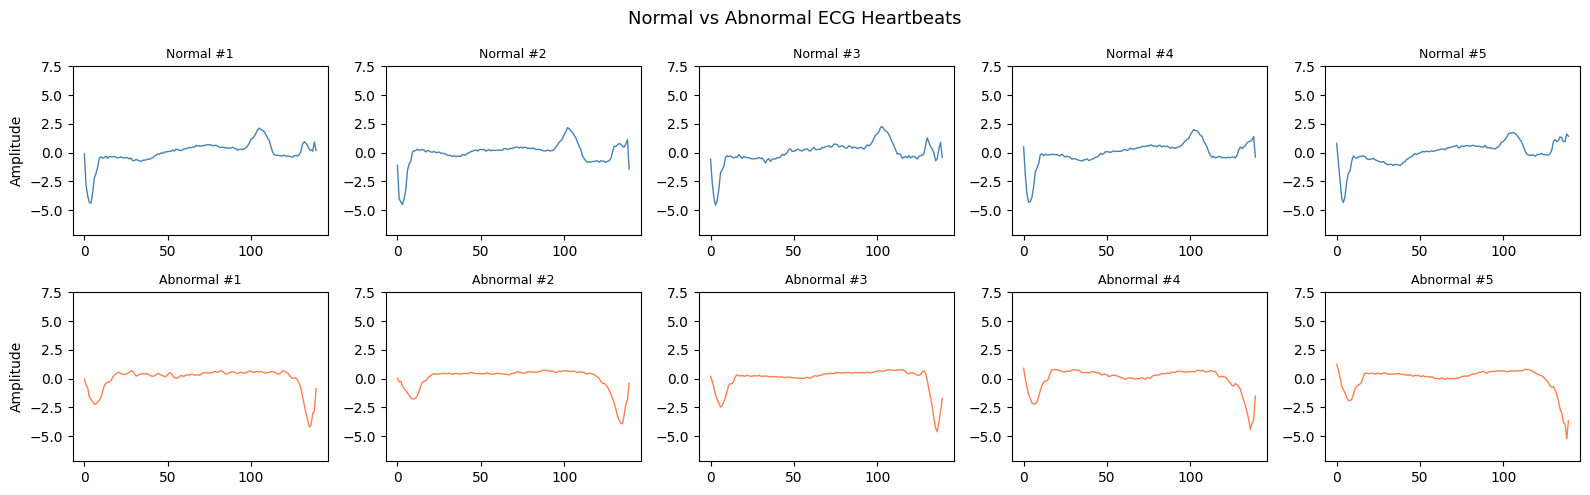

In [8]:
# Plot sample normal and abnormal heartbeats
fig, axes = plt.subplots(2, 5, figsize=(16, 5))

normal_idx = np.where(y_binary == 1)[0]
abnormal_idx = np.where(y_binary == 0)[0]

for i in range(5):
    axes[0, i].plot(X[normal_idx[i]], color='steelblue', linewidth=1)
    axes[0, i].set_title(f'Normal #{i+1}', fontsize=9)
    axes[0, i].set_ylim(X.min() - 0.1, X.max() + 0.1)
    if i == 0: axes[0, i].set_ylabel('Amplitude')
    
    axes[1, i].plot(X[abnormal_idx[i]], color='coral', linewidth=1)
    axes[1, i].set_title(f'Abnormal #{i+1}', fontsize=9)
    axes[1, i].set_ylim(X.min() - 0.1, X.max() + 0.1)
    if i == 0: axes[1, i].set_ylabel('Amplitude')

plt.suptitle('Normal vs Abnormal ECG Heartbeats', fontsize=13)
plt.tight_layout()
plt.show()

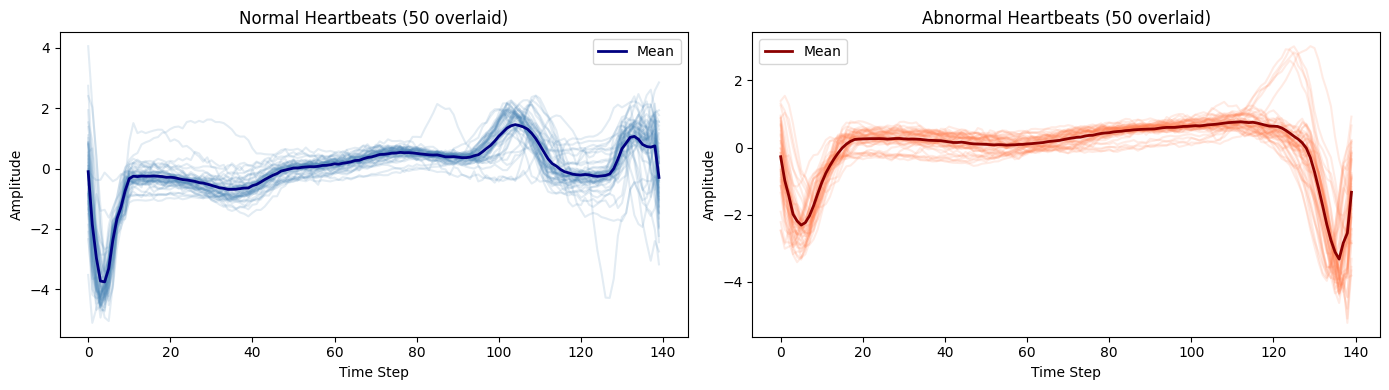

In [9]:
# Overlay many signals to see the variation
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for i in range(50):
    axes[0].plot(X[normal_idx[i]], alpha=0.15, color='steelblue')
    axes[1].plot(X[abnormal_idx[i]], alpha=0.15, color='coral')

axes[0].plot(X[normal_idx[:50]].mean(axis=0), color='navy', linewidth=2, label='Mean')
axes[1].plot(X[abnormal_idx[:50]].mean(axis=0), color='darkred', linewidth=2, label='Mean')

axes[0].set_title('Normal Heartbeats (50 overlaid)'); axes[0].legend()
axes[1].set_title('Abnormal Heartbeats (50 overlaid)'); axes[1].legend()
for ax in axes: ax.set_xlabel('Time Step'); ax.set_ylabel('Amplitude')
plt.tight_layout()
plt.show()

### 🤔 Questions

1. What visual differences do you observe between normal and abnormal heartbeats?
2. Are all abnormal signals obviously abnormal? Could a human easily distinguish them?
3. Looking at the overlay plots, is there more variation within normal or abnormal beats? Why might this matter for anomaly detection?

*Double-click here to write your answers...*

---
# Part 3: Learning Representations with Autoencoders

## The Core Idea

We train an autoencoder to compress and reconstruct ECG signals. The key design choice: **train on normal heartbeats only**.

Why? Because we want the model to learn *what normal looks like*. When it encounters an abnormal heartbeat, it won't know how to reconstruct it well — producing a high reconstruction error. This is the basis for anomaly detection.

```
Normal ECG → Encoder → Latent (16 numbers) → Decoder → Good reconstruction (low error)
Abnormal ECG → Encoder → Latent (16 numbers) → Decoder → Poor reconstruction (high error)
```

👉 **Note:** The train/validation/test split framework still applies. We train on the training set, tune hyperparameters using validation, and evaluate on the test set. The only difference is that no **labels** are used during training — the signals themselves are both input and target. For this lab we keep things simple, but in any practical application you should maintain proper splits.

## Task 3.1 — Prepare Data

In [10]:
# Split: train on NORMAL only, evaluate on ALL
# We hold out some normal beats for validation/testing too

normal_data = X[y_binary == 1]
abnormal_data = X[y_binary == 0]

# Split normal data: 70% train, 15% val, 15% test
normal_train, normal_temp = train_test_split(normal_data, test_size=0.3, random_state=42)
normal_val, normal_test = train_test_split(normal_temp, test_size=0.5, random_state=42)

# Split abnormal data: val and test only (we don't train on abnormal)
abnormal_val, abnormal_test = train_test_split(abnormal_data, test_size=0.5, random_state=42)

print(f'Training (normal only):  {len(normal_train)}')
print(f'Validation: {len(normal_val)} normal + {len(abnormal_val)} abnormal')
print(f'Test:       {len(normal_test)} normal + {len(abnormal_test)} abnormal')

# Convert to PyTorch tensors — shape (N, 1, 140) for Conv1d
def to_tensor(data):
    return torch.tensor(data, dtype=torch.float32).unsqueeze(1)  # add channel dim

train_tensor = to_tensor(normal_train)
train_loader = DataLoader(TensorDataset(train_tensor), batch_size=64, shuffle=True)

print(f'\nTensor shape: {train_tensor.shape}  (samples, channels, time_steps)')

Training (normal only):  2043
Validation: 438 normal + 1040 abnormal
Test:       438 normal + 1041 abnormal

Tensor shape: torch.Size([2043, 1, 140])  (samples, channels, time_steps)


## Task 3.2 — Build a 1D Convolutional Autoencoder

In [11]:
class Reshape1D(nn.Module):
    def __init__(self, *shape):
        super().__init__()
        self.shape = shape
    def forward(self, x):
        return x.view(x.size(0), *self.shape)


class ECGAutoencoder(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        
        # Encoder: (1, 140) → (32, 35) → latent_dim
        self.encoder = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=5, stride=2, padding=2),   # (16, 70)
            nn.ReLU(),
            nn.Conv1d(16, 32, kernel_size=5, stride=2, padding=2),  # (32, 35)
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(32 * 35, latent_dim),
        )
        
        # Decoder: latent_dim → (32, 35) → (1, 140)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32 * 35),
            nn.ReLU(),
            Reshape1D(32, 35),
            nn.ConvTranspose1d(32, 16, kernel_size=5, stride=2, padding=2, output_padding=1),  # (16, 70)
            nn.ReLU(),
            nn.ConvTranspose1d(16, 1, kernel_size=5, stride=2, padding=2, output_padding=1),   # (1, 140)
        )
    
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)
    
    def encode(self, x):
        return self.encoder(x)

# Verify shapes
ae = ECGAutoencoder(latent_dim=16)
test_input = torch.randn(1, 1, 140)
print(f'Input:  {test_input.shape}')
print(f'Latent: {ae.encode(test_input).shape}')
print(f'Output: {ae(test_input).shape}')
print(f'Parameters: {sum(p.numel() for p in ae.parameters()):,}')

Input:  torch.Size([1, 1, 140])
Latent: torch.Size([1, 16])
Output: torch.Size([1, 1, 140])
Parameters: 42,321


## Task 3.3 — Train the Autoencoder

  Epoch 1/50 — Loss: 0.716394
  Epoch 10/50 — Loss: 0.024510
  Epoch 20/50 — Loss: 0.015211
  Epoch 30/50 — Loss: 0.011587
  Epoch 40/50 — Loss: 0.010354
  Epoch 50/50 — Loss: 0.009580


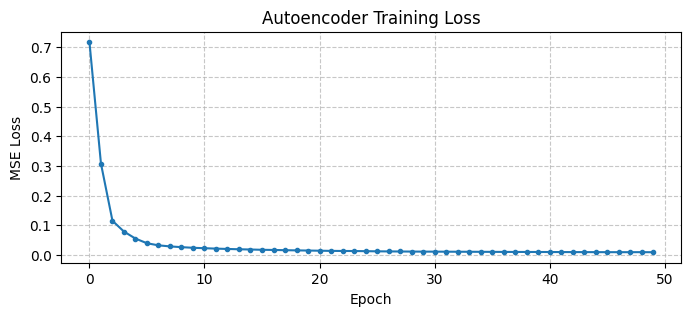

In [12]:
def train_autoencoder(model, train_loader, num_epochs=50, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    losses = []
    
    for epoch in range(num_epochs):
        model.train()
        epoch_loss = 0.0
        for (batch,) in train_loader:
            batch = batch.to(device)
            reconstructed = model(batch)
            loss = criterion(reconstructed, batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * batch.size(0)
        
        epoch_loss /= len(train_loader.dataset)
        losses.append(epoch_loss)
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f'  Epoch {epoch+1}/{num_epochs} — Loss: {epoch_loss:.6f}')
    
    return losses

ecg_ae = ECGAutoencoder(latent_dim=16).to(device)
ae_losses = train_autoencoder(ecg_ae, train_loader, num_epochs=50)

plt.figure(figsize=(8, 3))
plt.plot(ae_losses, marker='o', markersize=3)
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('Autoencoder Training Loss')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### 🤔 Questions

1. What does a healthy reconstruction loss curve look like?
2. What would overfitting look like?
3. How does latent dimension affect learning capacity?

*Double-click here to write your answers...*

---
# Part 4: Reconstruction Analysis

Let's see what the model has learned — can it reconstruct normal heartbeats? Does it struggle with abnormal ones?

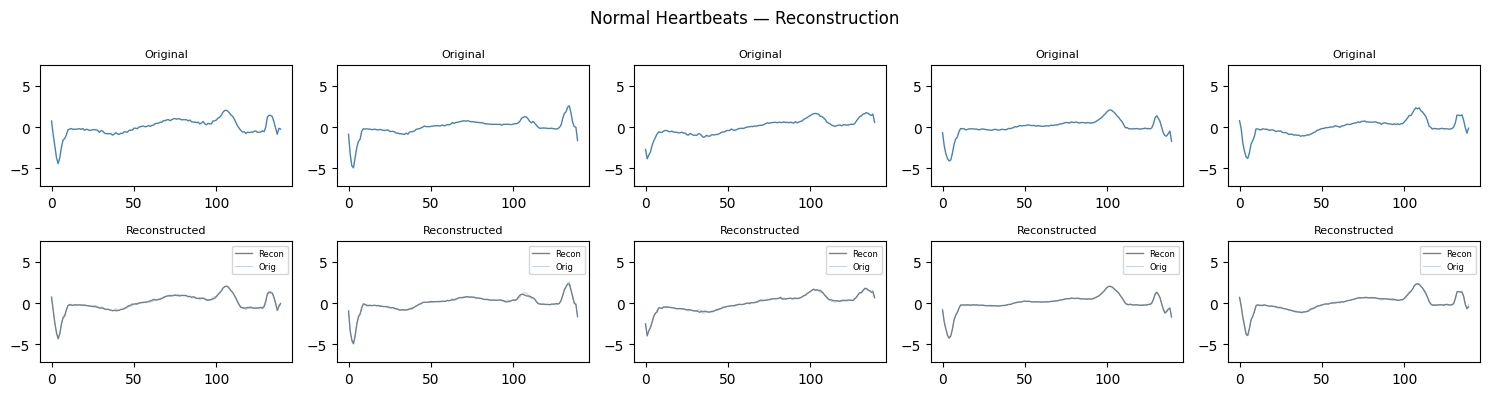

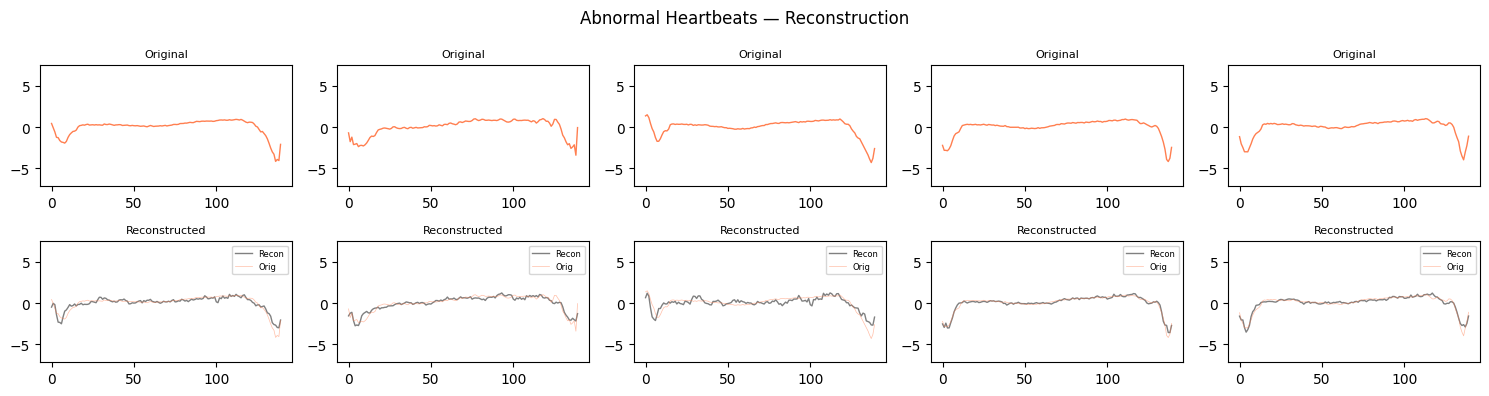

In [13]:
def plot_reconstructions(model, data, title, n=5, color='steelblue'):
    model.eval()
    fig, axes = plt.subplots(2, n, figsize=(n * 3, 4))
    
    for i in range(n):
        signal = to_tensor(data[i:i+1]).to(device)
        with torch.inference_mode():
            recon = model(signal).cpu().squeeze().numpy()
        original = data[i]
        
        axes[0, i].plot(original, color=color, linewidth=1)
        axes[0, i].set_title('Original', fontsize=8)
        axes[0, i].set_ylim(X.min() - 0.1, X.max() + 0.1)
        
        axes[1, i].plot(recon, color='gray', linewidth=1, label='Recon')
        axes[1, i].plot(original, color=color, linewidth=0.5, alpha=0.5, label='Orig')
        axes[1, i].set_title('Reconstructed', fontsize=8)
        axes[1, i].set_ylim(X.min() - 0.1, X.max() + 0.1)
        axes[1, i].legend(fontsize=6)
    
    plt.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()

plot_reconstructions(ecg_ae, normal_test, 'Normal Heartbeats — Reconstruction', color='steelblue')
plot_reconstructions(ecg_ae, abnormal_test, 'Abnormal Heartbeats — Reconstruction', color='coral')

### 🤔 Questions

1. Which type of heartbeat reconstructs better — normal or abnormal? Why?
2. What specific features of abnormal beats does the model fail to reconstruct?
3. How does this difference enable anomaly detection?

*Double-click here to write your answers...*

---
# Part 5: Latent Space Analysis

The encoder compresses each 140-step ECG signal into a 16-dimensional latent vector. Let's see if this representation has useful structure.

In [14]:
# Encode all test data
ecg_ae.eval()

all_test_data = np.vstack([normal_test, abnormal_test])
all_test_labels = np.concatenate([np.ones(len(normal_test)), np.zeros(len(abnormal_test))])

with torch.inference_mode():
    latents = ecg_ae.encode(to_tensor(all_test_data).to(device)).cpu().numpy()

print(f'Latent vectors shape: {latents.shape}')

Latent vectors shape: (1479, 16)


Running t-SNE...


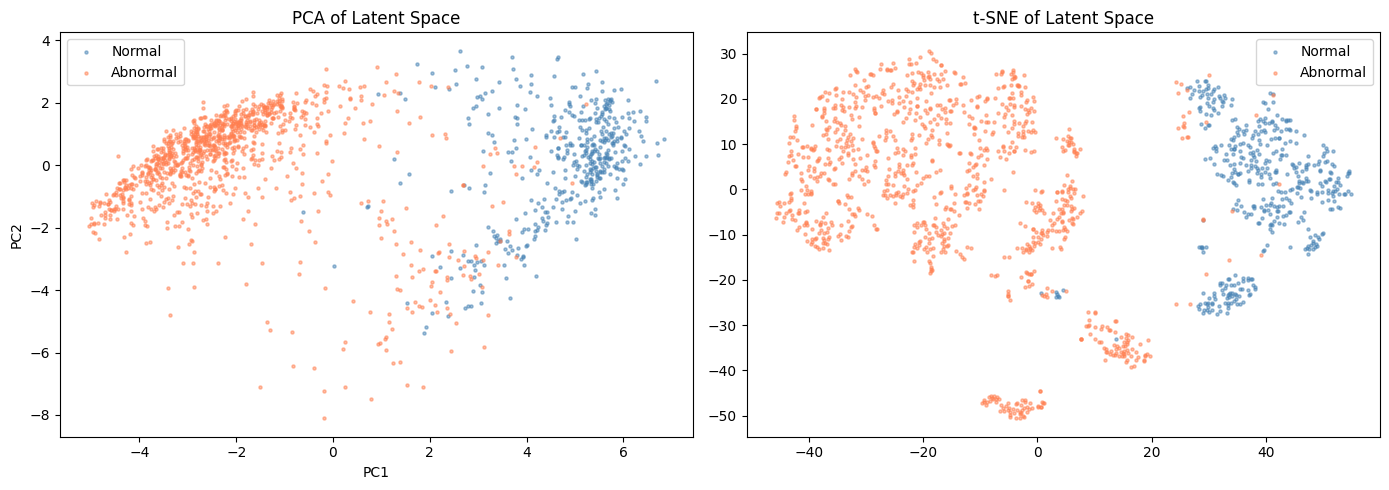

In [15]:
# PCA visualisation
pca = PCA(n_components=2)
latents_pca = pca.fit_transform(latents)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PCA
for label, name, color in [(1, 'Normal', 'steelblue'), (0, 'Abnormal', 'coral')]:
    mask = all_test_labels == label
    axes[0].scatter(latents_pca[mask, 0], latents_pca[mask, 1],
                    c=color, s=5, alpha=0.5, label=name)
axes[0].set_title('PCA of Latent Space'); axes[0].legend(); axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')

# t-SNE
print('Running t-SNE...')
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
latents_tsne = tsne.fit_transform(latents)

for label, name, color in [(1, 'Normal', 'steelblue'), (0, 'Abnormal', 'coral')]:
    mask = all_test_labels == label
    axes[1].scatter(latents_tsne[mask, 0], latents_tsne[mask, 1],
                    c=color, s=5, alpha=0.5, label=name)
axes[1].set_title('t-SNE of Latent Space'); axes[1].legend()

plt.tight_layout()
plt.show()

### 🤔 Questions

1. Do normal and abnormal signals separate in latent space? How well?
2. Remember: the autoencoder was trained on normal data **only**, with no labels. Yet the latent space shows structure. Why?
3. How could these latent representations be used for tasks other than anomaly detection?

*Double-click here to write your answers...*

---
# Part 6: Anomaly Detection Using Reconstruction Error

## The Key Idea

```
Normal signal  → trained model → Low reconstruction error  → NORMAL
Abnormal signal → trained model → High reconstruction error → ANOMALY
```

We set a **threshold** on the reconstruction error: anything above the threshold is flagged as an anomaly.

## Task 6.1 — Compute Reconstruction Errors

In [16]:
def compute_reconstruction_errors(model, data):
    model.eval()
    errors = []
    with torch.inference_mode():
        for i in range(0, len(data), 64):
            batch = to_tensor(data[i:i+64]).to(device)
            recon = model(batch)
            # Per-sample MSE
            mse = ((recon - batch) ** 2).mean(dim=(1, 2)).cpu().numpy()
            errors.extend(mse)
    return np.array(errors)

normal_errors = compute_reconstruction_errors(ecg_ae, normal_test)
abnormal_errors = compute_reconstruction_errors(ecg_ae, abnormal_test)

print(f'Normal errors  — Mean: {normal_errors.mean():.6f}, Std: {normal_errors.std():.6f}')
print(f'Abnormal errors — Mean: {abnormal_errors.mean():.6f}, Std: {abnormal_errors.std():.6f}')

Normal errors  — Mean: 0.009102, Std: 0.010303
Abnormal errors — Mean: 0.132567, Std: 0.077346


## Task 6.2 — Plot Error Distributions

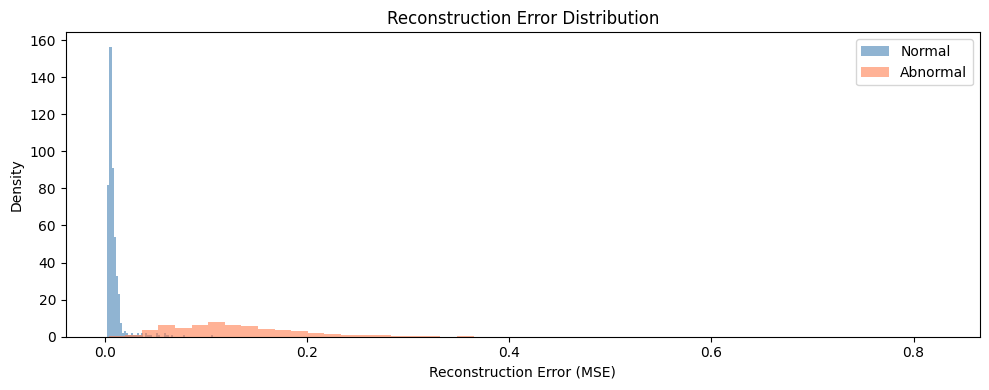

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(normal_errors, bins=50, alpha=0.6, color='steelblue', label='Normal', density=True)
ax.hist(abnormal_errors, bins=50, alpha=0.6, color='coral', label='Abnormal', density=True)
ax.set_xlabel('Reconstruction Error (MSE)')
ax.set_ylabel('Density')
ax.set_title('Reconstruction Error Distribution')
ax.legend()
plt.tight_layout()
plt.show()

## Task 6.3 — Choose a Threshold and Evaluate

In [18]:
# Combine errors and labels for evaluation
all_errors = np.concatenate([normal_errors, abnormal_errors])
all_labels = np.concatenate([np.zeros(len(normal_errors)), np.ones(len(abnormal_errors))])  # 0=normal, 1=anomaly

# Try different thresholds
# A good starting point: mean + 2*std of normal errors
threshold = normal_errors.mean() + 2 * normal_errors.std()
print(f'Threshold: {threshold:.6f}')

predictions = (all_errors > threshold).astype(int)  # 1 = anomaly

print(f'\nPrecision: {precision_score(all_labels, predictions):.4f}')
print(f'Recall:    {recall_score(all_labels, predictions):.4f}')
print(f'F1-score:  {f1_score(all_labels, predictions):.4f}')
print(f'Accuracy:  {accuracy_score(all_labels, predictions):.4f}')

Threshold: 0.029708

Precision: 0.9819
Recall:    0.9875
F1-score:  0.9847
Accuracy:  0.9784


## Task 6.4 — ROC Curve

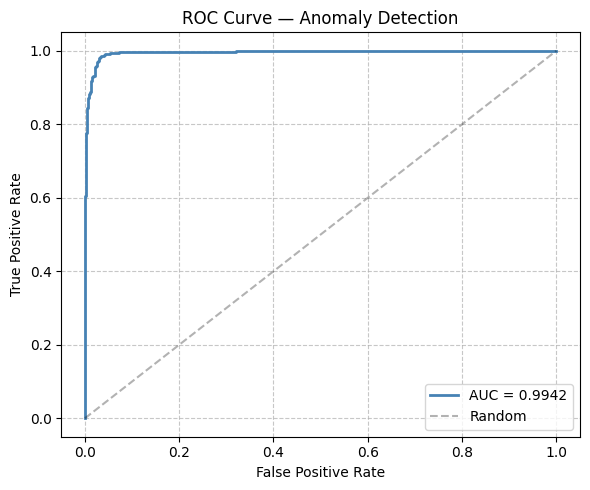

In [19]:
fpr, tpr, thresholds = roc_curve(all_labels, all_errors)
auc = roc_auc_score(all_labels, all_errors)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, color='steelblue', linewidth=2, label=f'AUC = {auc:.4f}')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve — Anomaly Detection')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 🤔 Questions

1. Why is accuracy a **poor** metric for anomaly detection? (Hint: what if 95% of data is normal?)
2. How did you choose the threshold? What trade-off exists between precision and recall?
3. In a medical setting, would you prioritise precision or recall? Why?
4. What does the ROC-AUC score tell you about the detector's quality?

*Double-click here to write your answers...*

---
# Part 7: Self-Supervised Learning — Denoising Autoencoder

## What Makes This Self-Supervised?

Our autoencoder creates its own learning target: the input IS the target. No human labels needed.

We can make the self-supervised task harder (and the representations better) by masking parts of the input:

| Pretext Task | Input | Target |
|---|---|---|
| Reconstruction | Clean ECG | Clean ECG |
| Denoising | Noisy ECG | Clean ECG |
| **Masked prediction** | ECG with gaps | Full ECG |

This is the 1D equivalent of BERT's masked language modelling: BERT masks random words and learns to predict them from context. We mask random time steps and learn to predict them from the surrounding signal.

👉 Why is this powerful? To fill in the gaps, the model must understand the structure of normal heartbeats — the relationship between the P-wave, QRS complex, and T-wave. This forces deeper understanding than simple reconstruction.

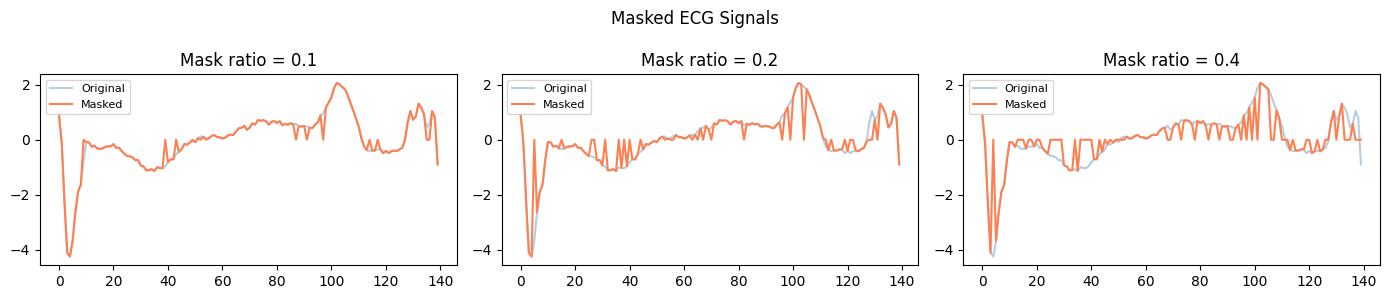

In [20]:
def mask_signal(signal, mask_ratio=0.15, mask_value=0.0):
    """Randomly mask a fraction of time steps in the signal."""
    masked = signal.clone()
    seq_len = signal.shape[-1]
    n_mask = int(seq_len * mask_ratio)
    
    for i in range(signal.shape[0]):  # per sample in batch
        # Randomly select time steps to mask
        mask_idx = torch.randperm(seq_len)[:n_mask]
        masked[i, :, mask_idx] = mask_value
    
    return masked


# Visualise what masking looks like
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
sample = to_tensor(normal_train[0:1])

for i, ratio in enumerate([0.1, 0.2, 0.4]):
    masked = mask_signal(sample, mask_ratio=ratio)
    axes[i].plot(sample.squeeze().numpy(), color='steelblue', alpha=0.4, label='Original')
    axes[i].plot(masked.squeeze().numpy(), color='coral', linewidth=1.5, label='Masked')
    axes[i].set_title(f'Mask ratio = {ratio}')
    axes[i].legend(fontsize=8)

plt.suptitle('Masked ECG Signals', fontsize=12)
plt.tight_layout()
plt.show()

In [21]:
def train_masked_ae(model, train_loader, mask_ratio=0.15, num_epochs=50, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    losses = []
    
    for epoch in range(num_epochs):
        model.train()
        epoch_loss = 0.0
        for (batch,) in train_loader:
            batch = batch.to(device)
            
            # Mask random time steps
            masked_batch = mask_signal(batch, mask_ratio=mask_ratio)
            
            # Reconstruct the FULL signal from the MASKED input
            reconstructed = model(masked_batch)
            loss = criterion(reconstructed, batch)  # target is the COMPLETE signal
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * batch.size(0)
        
        epoch_loss /= len(train_loader.dataset)
        losses.append(epoch_loss)
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f'  Epoch {epoch+1}/{num_epochs} — Loss: {epoch_loss:.6f}')
    return losses

masked_ae = ECGAutoencoder(latent_dim=16).to(device)
masked_losses = train_masked_ae(masked_ae, train_loader, mask_ratio=0.15, num_epochs=50)

  Epoch 1/50 — Loss: 0.550238
  Epoch 10/50 — Loss: 0.030499
  Epoch 20/50 — Loss: 0.022552
  Epoch 30/50 — Loss: 0.019203
  Epoch 40/50 — Loss: 0.016881
  Epoch 50/50 — Loss: 0.015003


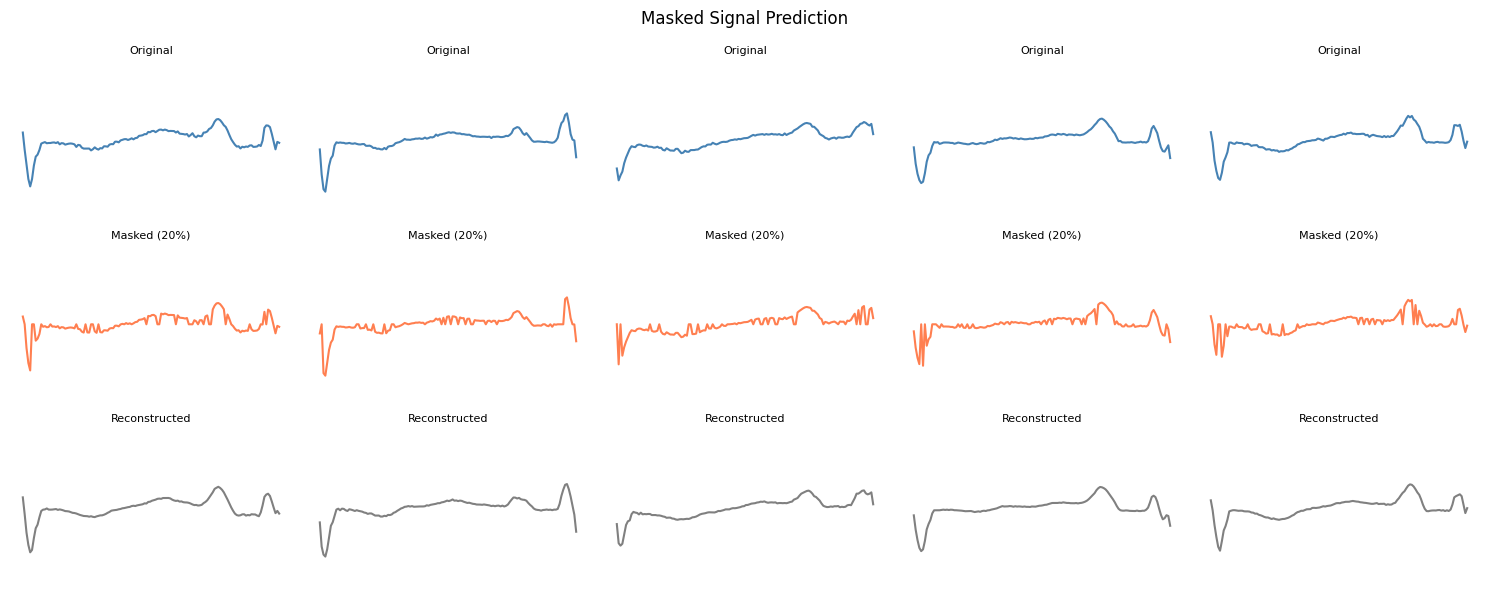

In [22]:
# Visualise: can the masked AE reconstruct from incomplete signals?
masked_ae.eval()
fig, axes = plt.subplots(3, 5, figsize=(15, 6))

for i in range(5):
    signal = to_tensor(normal_test[i:i+1])
    masked = mask_signal(signal, mask_ratio=0.2)
    
    with torch.inference_mode():
        recon = masked_ae(masked.to(device)).cpu()
    
    axes[0, i].plot(signal.squeeze().numpy(), color='steelblue')
    axes[0, i].set_title('Original', fontsize=8)
    axes[1, i].plot(masked.squeeze().numpy(), color='coral')
    axes[1, i].set_title('Masked (20%)', fontsize=8)
    axes[2, i].plot(recon.squeeze().numpy(), color='gray')
    axes[2, i].set_title('Reconstructed', fontsize=8)
    for row in range(3):
        axes[row, i].set_ylim(X.min() - 0.1, X.max() + 0.1)
        axes[row, i].axis('off')

axes[0, 0].set_ylabel('Original', fontsize=9)
axes[1, 0].set_ylabel('Masked', fontsize=9)
axes[2, 0].set_ylabel('Predicted', fontsize=9)
plt.suptitle('Masked Signal Prediction', fontsize=12)
plt.tight_layout()
plt.show()

In [23]:
# Compare anomaly detection: standard AE vs masked AE
masked_normal_err = compute_reconstruction_errors(masked_ae, normal_test)
masked_abnormal_err = compute_reconstruction_errors(masked_ae, abnormal_test)

masked_all_errors = np.concatenate([masked_normal_err, masked_abnormal_err])
masked_auc = roc_auc_score(all_labels, masked_all_errors)

print(f'Standard AE ROC-AUC: {auc:.4f}')
print(f'Masked AE ROC-AUC:   {masked_auc:.4f}')

Standard AE ROC-AUC: 0.9942
Masked AE ROC-AUC:   0.9909


### 🤔 Questions

1. Can the masked autoencoder successfully predict the missing time steps? How does the reconstruction look?
2. Does masked prediction produce better anomaly detection than standard reconstruction?
3. How is this directly analogous to BERT's masked language modelling? What plays the role of [MASK] tokens here?
4. Why might learning to predict missing parts force better representations than reconstructing the full signal?

*Double-click here to write your answers...*

---
# Part 8: Representation Transfer — Can Learned Features Help Classification?

The ultimate test of a representation: does it transfer to a downstream task? Let's compare:

- **Model A:** Pretrained encoder (frozen) + linear classifier
- **Model B:** Random encoder (no pretraining) + linear classifier
- **Model C:** Logistic regression directly on raw signals

This is the same paradigm as Week 5 (pretrained CNN → linear probing) and Week 9 (pretrained DistilBERT → LogReg).

In [24]:
# Use a small labelled dataset to simulate the scarce-label scenario
# Take only 100 labelled samples (50 normal, 50 abnormal)
np.random.seed(42)
few_normal = normal_data[np.random.choice(len(normal_data), 50, replace=False)]
few_abnormal = abnormal_data[np.random.choice(len(abnormal_data), 50, replace=False)]

few_X = np.vstack([few_normal, few_abnormal])
few_y = np.concatenate([np.ones(50), np.zeros(50)])

print(f'Labelled samples: {len(few_X)} (50 normal, 50 abnormal)')
print('This simulates the real-world scenario: very few labelled examples.')

Labelled samples: 100 (50 normal, 50 abnormal)
This simulates the real-world scenario: very few labelled examples.


In [25]:
# Model A: Pretrained encoder → LogReg
ecg_ae.eval()
with torch.inference_mode():
    pretrained_feats = ecg_ae.encode(to_tensor(few_X).to(device)).cpu().numpy()

clf_pretrained = LogisticRegression(max_iter=1000)
clf_pretrained.fit(pretrained_feats, few_y)

# Evaluate on test set
with torch.inference_mode():
    test_feats_pretrained = ecg_ae.encode(to_tensor(all_test_data).to(device)).cpu().numpy()
pretrained_acc = accuracy_score(all_test_labels, clf_pretrained.predict(test_feats_pretrained))

# Model B: Random encoder → LogReg
random_ae = ECGAutoencoder(latent_dim=16).to(device)  # no training!
random_ae.eval()
with torch.inference_mode():
    random_feats = random_ae.encode(to_tensor(few_X).to(device)).cpu().numpy()

clf_random = LogisticRegression(max_iter=1000)
clf_random.fit(random_feats, few_y)

with torch.inference_mode():
    test_feats_random = random_ae.encode(to_tensor(all_test_data).to(device)).cpu().numpy()
random_acc = accuracy_score(all_test_labels, clf_random.predict(test_feats_random))

# Model C: Raw signal → LogReg
clf_raw = LogisticRegression(max_iter=1000)
clf_raw.fit(few_X, few_y)
raw_acc = accuracy_score(all_test_labels, clf_raw.predict(all_test_data))

print(f'Classification accuracy with 100 labelled samples:')
print(f'  Model A (Pretrained encoder → LogReg): {pretrained_acc:.4f}')
print(f'  Model B (Random encoder → LogReg):     {random_acc:.4f}')
print(f'  Model C (Raw signal → LogReg):         {raw_acc:.4f}')

Classification accuracy with 100 labelled samples:
  Model A (Pretrained encoder → LogReg): 0.9777
  Model B (Random encoder → LogReg):     0.9108
  Model C (Raw signal → LogReg):         0.9730


### 🤔 Questions

1. Does the pretrained encoder outperform the random encoder? By how much?
2. How does this compare to using raw signals directly?
3. Why is this result significant? What does it demonstrate about representation learning?
4. How is this analogous to what we did with DistilBERT embeddings in Week 9 (feature extraction + LogReg)?

*Double-click here to write your answers...*

---
# Part 9: Mini Challenge

Choose **one**:

### Option A — Better Autoencoder
- Try deeper architectures, different latent dimensions, skip connections
- Compare reconstruction quality and anomaly detection AUC

### Option B — Better Anomaly Detector
- Try different thresholding strategies (percentile-based, validation-set tuned)
- Combine reconstruction error with latent-space distance
- Use the denoising AE instead of the standard AE

### Option C — Masked Signal Prediction
- Instead of denoising, mask random sections of the ECG and train the model to fill them in
- This is the 1D equivalent of BERT's masked language modelling
- Compare the representations to the standard and denoising autoencoders

In [ ]:
# Your code here
# ...

---
# Part 10: Reflection

1. What is representation learning, and why is it important?
2. Why can self-supervised learning reduce the need for labels?
3. Why are autoencoders effective for anomaly detection?
4. What makes a "good" latent representation? How can you evaluate representation quality?
5. How do the ideas in this lab connect to foundation models (Week 9)? What would happen if you scaled this approach to millions of ECG recordings?

*Double-click here to write your reflection...*

---
# Bonus (Optional)

- **Latent dimension sweep:** Compare latent_dim ∈ {2, 4, 8, 16, 32, 64} and plot AUC vs latent dim
- **UMAP visualisation:** Use UMAP instead of t-SNE for latent space plots
- **Variational Autoencoder:** Add KL divergence regularisation to the latent space
- **Multi-class anomaly detection:** Instead of binary (normal/abnormal), try to distinguish the 5 original ECG classes using latent representations


---

## 🔑 Key Takeaway

Representation learning is one of the most important ideas in modern AI. Rather than learning a single task from labels, models can learn useful representations from large amounts of **unlabelled** data and then transfer those representations to downstream tasks. In this lab, you used self-supervised learning to learn ECG representations and applied them to anomaly detection — a common real-world problem in healthcare AI where labelled data is scarce but unlabelled recordings are abundant.

This is the same principle that powers foundation models: pretrain on vast unlabelled data, then adapt to specific tasks with minimal supervision.
